## 다층 퍼셉트론(Multilayer Perceptron, MLP) 최적화 기법 — TensorFlow와 Keras 활용

### 7.2. Keras

- Keras의 핵심 데이터 구조는 모델(model)과 모델을 이루는 층(layer)이다.
- `Sequential`은 층을 순서대로 쌓는 입력에서 출력까지 한 방향으로 이어지는 간단한 구조의 신경망 모델이다.
- Keras 모델을 만드는 대표 방법은 `Sequential`, 함수형 API, `Model` 클래스를 상속하는 방법이다. 

In [1]:
from pathlib import Path  # 파일 경로 처리

import cv2  # 이미지 읽기와 전처리 
# pip install opencv-python
import matplotlib.pyplot as plt  # 학습 결과와 이미지 시각화
import numpy as np  # 배열 연산
import tensorflow as tf  # 신경망 생성과 학습

plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False 
# 음수 기호가 깨지는 현상 방지

#### 7.2.1. XOR을 학습하는 Multi Layer Perceptron

- @https://childult-programmer.tistory.com/46

In [ ]:
class XORClassifier:
    """XOR 입력과 정답으로 다층 퍼셉트론을 학습시키는 클래스"""

    def __init__(self, learning_rate = 0.3):
        """모델과 활성화 함수, 컴파일 단 정의, 초기화"""
        self.model = tf.keras.Sequential(
            [
                tf.keras.layers.Input(shape = (2,)),  # 입력값 두 개
                # 시그모이드 유닛 2개를 가진 레이어 추가
                tf.keras.layers.Dense(2, activation = "sigmoid"),  # 입력 조합을 학습하는 은닉층
                tf.keras.layers.Dense(1, activation = "sigmoid")  # XOR 결과 확률 출력
            ]
        )

        self.model.compile(
            optimizer = tf.keras.optimizers.SGD(learning_rate = learning_rate),
            # SGD로 가중치 갱신 (확률적 경사하강법)
            loss = "mean_squared_error",
            # 이진 출력에 대한 평균 제곱 오차 사용 
            # 정답과 예측 레이블 사이의 평균 제곱 오차
            # 이외에도 binaryCrossEntropy, CategoricalCrossEntropy
            metrics = ["accuracy"]
            # 성능평가지표 : 정확도
        )

    def train(self, inputs: np.ndarray, labels: np.ndarray, epochs = 10000):  # 입력과 정답으로 가중치 학습
        self.model.fit(
            inputs, labels, batch_size = 1, epochs = epochs, verbose = 0
        ) # XOR의 4가지 입력 조합과 정답 레이블을 통해 입력 한 건씩 가중치 갱신
        return inputs

    def predict(self, inputs):
        probabilities = self.model.predict(
            inputs, verbose = 0
        ) # 시그모이드 출력 확률을 임계값 0.5로 이진 분류
        return (probabilities >= 0.5).astype(int)

In [5]:
xor_classifier = XORClassifier()
xor_inputs = xor_classifier.train(
    inputs = np.array(
        [[0, 0], [0, 1], [1, 0], [1, 1]], 
        dtype=np.float32),
    labels = np.array(
        [[0], [1], [1], [0]], 
        dtype=np.float32)    
)

In [9]:
print("입력:\n", xor_inputs)
print("예측:\n", xor_classifier.predict(xor_inputs))

입력:
 [[0. 0.]
 [0. 1.]
 [1. 0.]
 [1. 1.]]
예측:
 [[0]
 [1]
 [1]
 [0]]


In [15]:
print( xor_classifier.model.summary() )

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 2)              │             6 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11 (48.00 B)

 Trainable params: 9 (36.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

None


#### 7.2.2. 숫자 가져와서 신경망 모델 구축하기

In [32]:
class MNISTDigitClassifier:
    """MNIST로 숫자를 학습하고 외부 이미지의 숫자를 예측하는 다층 퍼셉트론 클래스"""

    IMAGE_SIZE = 28  # MNIST 이미지 한 변의 픽셀 수
    NUM_CLASSES = 10  # 숫자 클래스 수 (0~9)

    def __init__(self, learning_rate=1e-3):
        self.learning_rate = learning_rate  # 학습률 저장
        self.model = self._build_model()  # 분류 신경망 생성
        self.history = None  # 학습 기록 저장 공간

    def _build_model(self):
        """28x28 픽셀을 입력받아 0~9 각 숫자의 확률을 출력"""
        model = tf.keras.Sequential([
            tf.keras.layers.Input(shape = (self.IMAGE_SIZE * self.IMAGE_SIZE,)),
            tf.keras.layers.Dense(512, activation = "relu"),  # 픽셀 특징을 학습하는 은닉층
            tf.keras.layers.Dense(self.NUM_CLASSES, activation = "sigmoid"),  # 숫자별 확률 출력
            # tf.keras.layers.Dense(self.NUM_CLASSES, activation = "softmax"),  # 숫자별 확률 출력
            # Dense layer : layer 안의 유닛들이 다른 layer의 뉴런들과 전부 연결된 형태의 layer
        ])
        model.compile(
            optimizer = "rmsprop",
            # optimizer = tf.keras.optimizers.Adam(learning_rate = self.learning_rate),
            loss = "mse",
            # 출력 10칸과 원-핫 정답 10칸을 칸별로 비교
            # loss = "sparse_categorical_crossentropy",
            metrics = ["categorical_accuracy"],  
            # 원-핫 정답용 정확도 (argmax끼리 비교)
            # metrics = ["accuracy"]
        )
        return model

    @staticmethod
    def _normalize_images(images):
        """(샘플 수, 28, 28) 이미지를 (샘플 수, 784)로 펼쳐 0~1로 정규화하는 데이터 전처리 메서드"""
        images = np.asarray(images, dtype = np.float32)
        return images.reshape((-1, 28 * 28)) / 255.0

    def load_data(self):
        """Keras에서 MNIST를 받아 학습/검증 입력을 준비하는 메서드"""
        (train_images, train_labels), (test_images, test_labels) = (
            tf.keras.datasets.mnist.load_data()
        )
        self.train_images = self._normalize_images(train_images)
        self.test_images = self._normalize_images(test_images)

        # MSE 손실은 출력(10칸)과 정답의 모양이 같아야 하므로 원-핫 인코딩
        self.train_labels = tf.keras.utils.to_categorical(train_labels, self.NUM_CLASSES)
        self.test_labels = tf.keras.utils.to_categorical(test_labels, self.NUM_CLASSES)
        # 예: 7 → [0,0,0,0,0,0,0,1,0,0], 형태 (60000,) → (60000, 10)

        # 레이블은 정수 0~9로 유지, 원-핫 인코딩은 하지 않음
        # self.train_labels = train_labels.astype(np.int64)
        # self.test_labels = test_labels.astype(np.int64)
        return self

    def train(self, epochs=5, batch_size=128, validation_split=0.1):
        """학습 데이터로 모델을 학습하고 학습 이력을 저장하는 메서드"""
        if not hasattr(self, "train_images"):
            raise RuntimeError("먼저 load_data()를 호출하세요.")
        self.history = self.model.fit(
            self.train_images,
            self.train_labels,
            epochs = epochs,
            batch_size = batch_size,
            validation_split = validation_split,
            verbose = 1,
        )
        return self.history

    def evaluate(self):
        """테스트 데이터의 손실과 정확도를 반환하는 메서드"""
        if not hasattr(self, "test_images"):
            raise RuntimeError("먼저 load_data()를 호출하세요.")
        return self.model.evaluate(self.test_images, self.test_labels, verbose = 1)

    def prepare_image(self, image_path):
        """파일 이미지를 MNIST에 맞는 정규화된 28x28 입력으로 변환합니다."""
        image_path = Path(image_path)
        image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
        if image is None:
            raise FileNotFoundError(f"이미지를 읽을 수 없습니다: {image_path}")

        # 배경이 흰 이미지라면 MNIST와 같이 어두운 배경/밝은 숫자로 반전
        if image.mean() > 127:
            image = 255 - image

        # 가장자리에 여백을 두고 숫자 영역을 정사각형으로 만들어 비율을 보존
        foreground = cv2.threshold(image, 20, 255, cv2.THRESH_BINARY)[1]
        points = cv2.findNonZero(foreground)
        if points is not None:
            x, y, width, height = cv2.boundingRect(points)
            digit = image[y:y + height, x:x + width]
            side = int(max(width, height) * 1.4)
            # [To-be] 숫자 크기의 1.4배로 정사각형 만들어 여백 확보
            # side = max(width, height) + 8
            # [As-is] 여백이 8pixel로 고정되어 큰 이미지상 여백 거의 없음
            square = np.zeros((side, side), dtype=np.uint8)
            x_offset = (side - width) // 2
            y_offset = (side - height) // 2
            square[y_offset:y_offset + height, x_offset:x_offset + width] = digit
            image = square

        image = cv2.resize(
            image, (self.IMAGE_SIZE, self.IMAGE_SIZE), interpolation=cv2.INTER_AREA
        )
        return image.astype(np.float32).reshape(1, -1) / 255.0

    def predict_image(self, image_path):
        """이미지 파일을 분류해 예측 숫자와 클래스별 확률을 반환합니다."""
        image = self.prepare_image(image_path)
        probabilities = self.model.predict(image, verbose = 0)[0]
        return int(np.argmax(probabilities)), probabilities

In [33]:
classifier = MNISTDigitClassifier()  # MNIST 숫자 분류기 생성
classifier.load_data()  # MNIST 데이터 로드와 정규화
print("학습 입력 형태:", classifier.train_images.shape)
print("학습 레이블 형태:", classifier.train_labels.shape)

history = classifier.train(epochs = 5, batch_size = 128)

학습 입력 형태: (60000, 784)
학습 레이블 형태: (60000, 10)
Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - categorical_accuracy: 0.8626 - loss: 0.0272 - val_categorical_accuracy: 0.9360 - val_loss: 0.0131
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - categorical_accuracy: 0.9268 - loss: 0.0137 - val_categorical_accuracy: 0.9507 - val_loss: 0.0097
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - categorical_accuracy: 0.9424 - loss: 0.0107 - val_categorical_accuracy: 0.9613 - val_loss: 0.0079
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - categorical_accuracy: 0.9520 - loss: 0.0090 - val_categorical_accuracy: 0.9663 - val_loss: 0.0069
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - categorical_accuracy: 0.9584 - loss: 0.0079 - val_categorical_accuracy: 0.9682 - val_loss: 0.0062


In [34]:
test_loss, test_accuracy = classifier.evaluate()
print(f"테스트 손실: {test_loss:.4f}")
print(f"테스트 정확도: {test_accuracy:.2%}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 392us/step - categorical_accuracy: 0.9598 - loss: 0.0074
테스트 손실: 0.0074
테스트 정확도: 95.98%


#### 7.2.3. 학습 결과 시각화

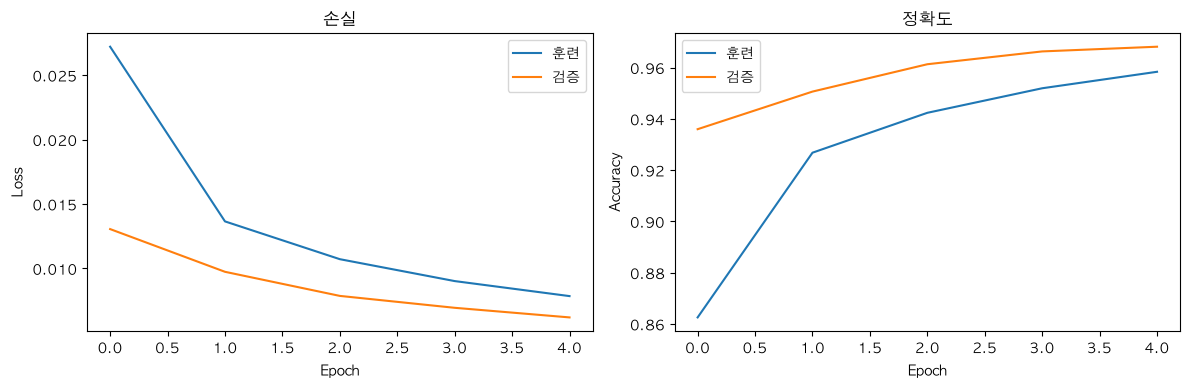

In [35]:
fig, axes = plt.subplots(1, 2, figsize = (12, 4))
axes[0].plot(history.history["loss"], label = "훈련")
axes[0].plot(history.history["val_loss"], label = "검증")
axes[0].set(title = "손실", xlabel = "Epoch", ylabel = "Loss")
axes[0].legend()

axes[1].plot(history.history["categorical_accuracy"], label = "훈련")
axes[1].plot(history.history["val_categorical_accuracy"], label = "검증")
axes[1].set(title = "정확도", xlabel = "Epoch", ylabel = "Accuracy")
axes[1].legend()
plt.tight_layout()
plt.show()

#### 7.2.4. `test.png` 불러와 예측하기

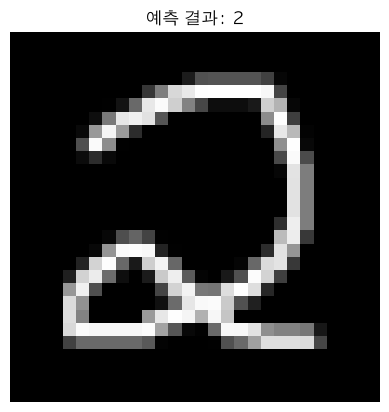

예측 숫자: 2
클래스별 확률: [0.036 0.    0.876 0.008 0.    0.004 0.009 0.    0.    0.   ]


In [36]:
# 현재 폴더와 노트북 폴더의 dataArchive에서 test.png 검색
notebook_dir = Path("FundamentalDeepLearning/Optimization")  # 프로젝트 루트 기준 노트북 경로
image_candidates = [
    Path("test.png"),  # 현재 작업 폴더
    Path("dataArchive/test.png"),  # 노트북 폴더에서 실행할 때
    notebook_dir / "test.png",  # 프로젝트 루트에서 실행할 때
    notebook_dir / "dataArchive/test.png",  # 프로젝트 루트 기준 dataArchive
]  # 확인할 이미지 경로
image_path = next((path for path in image_candidates if path.is_file()), None)  # 존재하는 첫 파일 선택

if image_path is None:  # 이미지가 없으면 예측 생략
    print("test.png 파일이 없어 이미지 예측을 건너뜁니다. test.png를 노트북 폴더에 넣고 다시 실행하세요.")
    
else:  # 이미지 분류와 시각화
    predicted_digit, probabilities = classifier.predict_image(image_path)  # 숫자와 클래스별 확률 예측
    processed_image = classifier.prepare_image(image_path).reshape(28, 28)  # 전처리 이미지를 28x28로 변환

    plt.imshow(processed_image, cmap = "gray")  # 모델 입력 이미지 표시
    plt.title(f"예측 결과: {predicted_digit}")  # 예측 숫자를 제목으로 표시
    plt.axis("off")  # 좌표축 숨기기
    plt.show()  # 그림 출력

    print(f"예측 숫자: {predicted_digit}")  # 예측 숫자 출력 # 2가 아닌 3 ? 0?
    print("클래스별 확률:", np.round(probabilities, 3))  # 숫자별 확률 출력 

---

#### 7.2.5. Grid Search